In [58]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler

# Load labelled data
df = pd.read_csv("../data/processed/kerala_flood_labeled.csv")

months = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"
]

cutoffs = {
    "March": months[:3],
    "May": months[:5],
    "June": months[:6],
    "July": months[:7],
    "September": months[:9]
}

y = df["FLOOD_LABEL"]

# Define the five required classifiers
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=2, random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5, weights="distance"
    ),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(
        kernel="rbf", C=1.0, random_state=42
    )
}

# Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42
)

results = []
prediction_records = []
fold_metrics_records = []

for cutoff, columns in cutoffs.items():

    X = df[columns]

    for model_name, estimator in models.items():

        oof_predictions = np.zeros(len(df), dtype=int)
        oof_probabilities = np.zeros(len(df))
        oof_folds = np.zeros(len(df), dtype=int)

        for fold_number, (train_idx, val_idx) in enumerate(
            cv.split(X, y), start=1
        ):

            pipeline = Pipeline([
                ("scaler", StandardScaler()),
                ("oversampler", RandomOverSampler(random_state=42)),
                ("classifier", estimator)
            ])

            pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])

            oof_predictions[val_idx] = pipeline.predict(
                X.iloc[val_idx]
            )

            if model_name == "SVM":
                oof_probabilities[val_idx] = pipeline.decision_function(
                    X.iloc[val_idx]
                )
            else:
                oof_probabilities[val_idx] = pipeline.predict_proba(
                    X.iloc[val_idx]
                )[:, 1]

            # Store the validation fold for each observation
            oof_folds[val_idx] = fold_number

            # Evaluate this individual validation fold
            fold_y_true = y.iloc[val_idx]
            fold_y_pred = oof_predictions[val_idx]
            fold_scores = oof_probabilities[val_idx]

            tn, fp, fn, tp = confusion_matrix(
                fold_y_true,
                fold_y_pred,
                labels=[0, 1]
            ).ravel()

            fold_metrics_records.append({
                "Warning Window": cutoff,
                "Model": model_name,
                "Fold": fold_number,
                "Validation Years": ", ".join(
                    map(str, df.iloc[val_idx]["YEAR"].tolist())
                ),
                "TP": tp,
                "FN": fn,
                "FP": fp,
                "TN": tn,
                "Recall": recall_score(
                    fold_y_true, fold_y_pred, zero_division=0
                ),
                "Precision": precision_score(
                    fold_y_true, fold_y_pred, zero_division=0
                ),
                "F1 Score": f1_score(
                    fold_y_true, fold_y_pred, zero_division=0
                ),
                "ROC-AUC": roc_auc_score(
                    fold_y_true, fold_scores
                ),
                "PR-AUC (Average Precision)": average_precision_score(
                    fold_y_true, fold_scores
                )
            })

        results.append({
            "Warning Window": cutoff,
            "Model": model_name,
            "Recall": recall_score(y, oof_predictions, zero_division=0),
            "F1 Score": f1_score(y, oof_predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y, oof_probabilities),
            "PR-AUC (Average Precision)": average_precision_score(y, oof_probabilities)
        })

        prediction_records.append(pd.DataFrame({
            "YEAR": df["YEAR"],
            "CUTOFF": cutoff,
            "MODEL": model_name,
            "FOLD": oof_folds,
            "ACTUAL": y,
            "PREDICTED": oof_predictions,
            "PROBABILITY": oof_probabilities
        }))

# Create comparison table
results_df = pd.DataFrame(results)

display(
    results_df.round(3).sort_values(
        ["Warning Window", "F1 Score"],
        ascending=[True, False]
    )
)

print("\nModels evaluated:", len(models))
print("Warning windows:", len(cutoffs))
print("Total experiments:", len(results_df))
print("Cross-validation folds:", cv.get_n_splits())

,Warning Window,Model,Recall,F1 Score,ROC-AUC,PR-AUC (Average Precision)
15,July,Logistic Regression,0.500,0.222,0.709,0.247
16,July,Decision Tree,0.333,0.211,0.613,0.078
18,July,Naive Bayes,0.167,0.077,0.476,0.064
17,July,KNN,0.000,0.000,0.419,0.051
19,July,SVM,0.000,0.000,0.446,0.057
10,June,Logistic Regression,0.667,0.296,0.677,0.115
11,June,Decision Tree,0.333,0.174,0.592,0.068
13,June,Naive Bayes,0.167,0.062,0.420,0.052
12,June,KNN,0.000,0.000,0.396,0.051
14,June,SVM,0.000,0.000,0.275,0.039



Models evaluated: 5
Warning windows: 5
Total experiments: 25
Cross-validation folds: 3


In [59]:

# SUPPLEMENTARY EXPERIMENT:
# Baseline and Imbalance-Handling Comparison

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler

supplementary_results = []

# Three approaches to compare
comparison_models = {
    "Dummy Classifier": "dummy",
    "Class-Weighted Logistic Regression": "weighted",
    "RandomOverSampler Logistic Regression": "oversampling"
}

for cutoff, columns in cutoffs.items():

    X = df[columns]

    for model_name, approach in comparison_models.items():

        oof_predictions = np.zeros(len(df), dtype=int)
        oof_scores = np.zeros(len(df))

        for train_idx, val_idx in cv.split(X, y):

            if approach == "dummy":

                estimator = DummyClassifier(
                    strategy="prior"
                )

            elif approach == "weighted":

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42,
                        class_weight="balanced"
                    ))
                ])

            else:

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("oversampler", RandomOverSampler(
                        random_state=42
                    )),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42
                    ))
                ])

            estimator.fit(
                X.iloc[train_idx],
                y.iloc[train_idx]
            )

            oof_predictions[val_idx] = estimator.predict(
                X.iloc[val_idx]
            )

            oof_scores[val_idx] = estimator.predict_proba(
                X.iloc[val_idx]
            )[:, 1]

        supplementary_results.append({
            "Warning Window": cutoff,
            "Approach": model_name,
            "Recall": recall_score(
                y, oof_predictions, zero_division=0
            ),
            "Precision": precision_score(
                y, oof_predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y, oof_predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y, oof_scores
            ),
            "PR-AUC (Average Precision)": average_precision_score(
                y, oof_scores
            )
        })

# Create supplementary comparison table
supplementary_results_df = pd.DataFrame(
    supplementary_results
)

display(
    supplementary_results_df.round(3).sort_values(
        ["Warning Window", "F1 Score"],
        ascending=[True, False]
    )
)

# Save supplementary results separately
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

supplementary_results_df.to_csv(
    output_dir / "supplementary_baseline_comparison.csv",
    index=False
)

print("Supplementary experiments:", len(supplementary_results_df))
print("Saved supplementary baseline comparison successfully.")


,Warning Window,Approach,Recall,Precision,F1 Score,ROC-AUC,PR-AUC (Average Precision)
10,July,Class-Weighted Logistic Regression,0.500,0.150,0.231,0.730,0.257
11,July,RandomOverSampler Logistic Regression,0.500,0.143,0.222,0.709,0.247
9,July,Dummy Classifier,0.000,0.000,0.000,0.500,0.051
8,June,RandomOverSampler Logistic Regression,0.667,0.190,0.296,0.677,0.115
7,June,Class-Weighted Logistic Regression,0.667,0.182,0.286,0.679,0.116
6,June,Dummy Classifier,0.000,0.000,0.000,0.500,0.051
2,March,RandomOverSampler Logistic Regression,0.333,0.043,0.077,0.377,0.048
1,March,Class-Weighted Logistic Regression,0.333,0.043,0.075,0.362,0.046
0,March,Dummy Classifier,0.000,0.000,0.000,0.500,0.051
3,May,Dummy Classifier,0.000,0.000,0.000,0.500,0.051


Supplementary experiments: 15
Saved supplementary baseline comparison successfully.


In [60]:

# THRESHOLD SENSITIVITY ANALYSIS
# Supplementary Logistic Regression Experiments

thresholds = [0.25, 0.35, 0.50, 0.65, 0.75]

approaches = ["Class-Weighted", "RandomOverSampler"]

threshold_predictions = []

for cutoff, columns in cutoffs.items():

    X = df[columns]

    for approach in approaches:

        oof_scores = np.zeros(len(df))

        for train_idx, val_idx in cv.split(X, y):

            if approach == "Class-Weighted":

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42,
                        class_weight="balanced"
                    ))
                ])

            else:

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("oversampler", RandomOverSampler(
                        random_state=42
                    )),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42
                    ))
                ])

            estimator.fit(
                X.iloc[train_idx],
                y.iloc[train_idx]
            )

            oof_scores[val_idx] = estimator.predict_proba(
                X.iloc[val_idx]
            )[:, 1]

        # Evaluate different thresholds on pooled OOF scores
        for threshold in thresholds:

            predictions = (
                oof_scores >= threshold
            ).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                y,
                predictions,
                labels=[0, 1]
            ).ravel()

            threshold_predictions.append({
                "Warning Window": cutoff,
                "Approach": approach,
                "Threshold": threshold,
                "Recall": recall_score(
                    y, predictions, zero_division=0
                ),
                "Precision": precision_score(
                    y, predictions, zero_division=0
                ),
                "F1 Score": f1_score(
                    y, predictions, zero_division=0
                ),
                "TP": tp,
                "FP": fp,
                "FN": fn,
                "TN": tn
            })

threshold_results_df = pd.DataFrame(
    threshold_predictions
)

display(
    threshold_results_df.round(3).sort_values(
        ["Warning Window", "Approach", "Threshold"]
    )
)

# Save results separately
threshold_results_df.to_csv(
    output_dir / "threshold_sensitivity_analysis.csv",
    index=False
)

print("Threshold experiments:", len(threshold_results_df))
print("Threshold sensitivity analysis saved successfully.")


,Warning Window,Approach,Threshold,Recall,Precision,F1 Score,TP,FP,FN,TN
30,July,Class-Weighted,0.25,0.667,0.118,0.200,4,30,2,81
31,July,Class-Weighted,0.35,0.667,0.138,0.229,4,25,2,86
32,July,Class-Weighted,0.50,0.500,0.150,0.231,3,17,3,94
33,July,Class-Weighted,0.65,0.500,0.188,0.273,3,13,3,98
34,July,Class-Weighted,0.75,0.333,0.182,0.235,2,9,4,102
35,July,RandomOverSampler,0.25,0.667,0.125,0.211,4,28,2,83
36,July,RandomOverSampler,0.35,0.667,0.143,0.235,4,24,2,87
37,July,RandomOverSampler,0.50,0.500,0.143,0.222,3,18,3,93
38,July,RandomOverSampler,0.65,0.500,0.176,0.261,3,14,3,97
39,July,RandomOverSampler,0.75,0.333,0.182,0.235,2,9,4,102


Threshold experiments: 50
Threshold sensitivity analysis saved successfully.


In [61]:

# SUPPLEMENTARY EXPERIMENT:
# TIME-ORDERED VALIDATION

from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Ensure observations are chronologically ordered
time_df = df.sort_values("YEAR").reset_index(drop=True)

time_y = time_df["FLOOD_LABEL"]

# Expanding-window validation
time_cv = TimeSeriesSplit(n_splits=3)

time_results = []
time_prediction_records = []

time_approaches = {
    "Dummy Classifier": "dummy",
    "Class-Weighted Logistic Regression": "weighted",
    "RandomOverSampler Logistic Regression": "oversampling"
}

for cutoff, columns in cutoffs.items():

    X_time = time_df[columns]

    for approach_name, approach in time_approaches.items():

        all_predictions = []
        all_scores = []
        all_actual = []
        all_years = []

        for fold_number, (train_idx, val_idx) in enumerate(
            time_cv.split(X_time), start=1
        ):

            X_train = X_time.iloc[train_idx]
            X_val = X_time.iloc[val_idx]

            y_train = time_y.iloc[train_idx]
            y_val = time_y.iloc[val_idx]

            if approach == "dummy":

                estimator = DummyClassifier(
                    strategy="prior"
                )

            elif approach == "weighted":

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42,
                        class_weight="balanced"
                    ))
                ])

            else:

                estimator = Pipeline([
                    ("scaler", StandardScaler()),
                    ("oversampler", RandomOverSampler(
                        random_state=42
                    )),
                    ("classifier", LogisticRegression(
                        max_iter=2000,
                        random_state=42
                    ))
                ])

            estimator.fit(X_train, y_train)

            predictions = estimator.predict(X_val)

            scores = estimator.predict_proba(X_val)[:, 1]

            all_predictions.extend(predictions)
            all_scores.extend(scores)
            all_actual.extend(y_val.tolist())

            validation_years = time_df.iloc[val_idx]["YEAR"].tolist()
            all_years.extend(validation_years)

            time_prediction_records.append(
                pd.DataFrame({
                    "YEAR": validation_years,
                    "CUTOFF": cutoff,
                    "APPROACH": approach_name,
                    "FOLD": fold_number,
                    "ACTUAL": y_val.to_numpy(),
                    "PREDICTED": predictions,
                    "SCORE": scores
                })
            )

        # Pooled chronological validation results
        time_results.append({
            "Warning Window": cutoff,
            "Approach": approach_name,
            "Recall": recall_score(
                all_actual, all_predictions, zero_division=0
            ),
            "Precision": precision_score(
                all_actual, all_predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                all_actual, all_predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                all_actual, all_scores
            ),
            "PR-AUC (Average Precision)": average_precision_score(
                all_actual, all_scores
            ),
            "Validation Positives": int(sum(all_actual)),
            "Validation Observations": len(all_actual)
        })

time_results_df = pd.DataFrame(time_results)

display(time_results_df.round(3))

# Save results separately
time_results_df.to_csv(
    output_dir / "time_ordered_validation_results.csv",
    index=False
)

time_predictions_df = pd.concat(
    time_prediction_records,
    ignore_index=True
)

time_predictions_df.to_csv(
    output_dir / "time_ordered_oof_predictions.csv",
    index=False
)

print("Time-ordered experiments:", len(time_results_df))
print("Validation observations per experiment:",
      time_results_df["Validation Observations"].unique())

print("Saved time-ordered validation results successfully.")


,Warning Window,Approach,Recall,Precision,F1 Score,ROC-AUC,PR-AUC (Average Precision),Validation Positives,Validation Observations
0,March,Dummy Classifier,0.0,0.000,0.000,0.641,0.087,5,87
1,March,Class-Weighted Logistic Regression,0.2,0.056,0.087,0.473,0.069,5,87
2,March,RandomOverSampler Logistic Regression,0.2,0.053,0.083,0.488,0.070,5,87
3,May,Dummy Classifier,0.0,0.000,0.000,0.641,0.087,5,87
4,May,Class-Weighted Logistic Regression,0.0,0.000,0.000,0.410,0.055,5,87
5,May,RandomOverSampler Logistic Regression,0.0,0.000,0.000,0.429,0.057,5,87
6,June,Dummy Classifier,0.0,0.000,0.000,0.641,0.087,5,87
7,June,Class-Weighted Logistic Regression,0.2,0.083,0.118,0.707,0.121,5,87
8,June,RandomOverSampler Logistic Regression,0.2,0.083,0.118,0.680,0.109,5,87
9,July,Dummy Classifier,0.0,0.000,0.000,0.641,0.087,5,87


Time-ordered experiments: 15
Validation observations per experiment: [87]
Saved time-ordered validation results successfully.


In [62]:
# TIME-ORDERED VALIDATION: FOLD-WISE METRICS

time_fold_records = []

for (cutoff, approach, fold), group in (
    time_predictions_df.groupby(
        ["CUTOFF", "APPROACH", "FOLD"]
    )
):

    y_true = group["ACTUAL"]
    y_pred = group["PREDICTED"]
    scores = group["SCORE"]

    time_fold_records.append({

        "Warning Window": cutoff,
        "Approach": approach,
        "Fold": fold,

        "Validation Observations": len(group),
        "Positive Years": int(y_true.sum()),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true, scores
        ),

        "PR-AUC (Average Precision)": average_precision_score(
            y_true, scores
        )
    })

time_fold_metrics_df = pd.DataFrame(time_fold_records)

display(
    time_fold_metrics_df.round(3).sort_values(
        ["Warning Window", "Approach", "Fold"]
    )
)

# Calculate mean and standard deviation across folds
time_fold_summary_df = (
    time_fold_metrics_df
    .groupby(["Warning Window", "Approach"])
    .agg(
        Recall_Mean=("Recall", "mean"),
        Recall_Std=("Recall", "std"),
        F1_Mean=("F1 Score", "mean"),
        F1_Std=("F1 Score", "std"),
        ROC_AUC_Mean=("ROC-AUC", "mean"),
        ROC_AUC_Std=("ROC-AUC", "std"),
        PR_AUC_Mean=("PR-AUC (Average Precision)", "mean"),
        PR_AUC_Std=("PR-AUC (Average Precision)", "std")
    )
    .reset_index()
    .round(3)
)

display(time_fold_summary_df)

# Save fold-level outputs
time_fold_metrics_df.to_csv(
    output_dir / "time_ordered_fold_metrics.csv",
    index=False
)

time_fold_summary_df.to_csv(
    output_dir / "time_ordered_fold_summary.csv",
    index=False
)

print("Fold-level experiments:", len(time_fold_metrics_df))
print("Fold summary experiments:", len(time_fold_summary_df))
print("Time-ordered fold-wise evaluation saved successfully.")


,Warning Window,Approach,Fold,Validation Observations,Positive Years,Recall,Precision,F1 Score,ROC-AUC,PR-AUC (Average Precision)
0,July,Class-Weighted Logistic Regression,1,29,1,0.000,0.000,0.000,0.607,0.083
1,July,Class-Weighted Logistic Regression,2,29,1,1.000,0.333,0.500,0.929,0.333
2,July,Class-Weighted Logistic Regression,3,29,3,0.000,0.000,0.000,0.718,0.237
3,July,Dummy Classifier,1,29,1,0.000,0.000,0.000,0.500,0.034
4,July,Dummy Classifier,2,29,1,0.000,0.000,0.000,0.500,0.034
5,July,Dummy Classifier,3,29,3,0.000,0.000,0.000,0.500,0.103
6,July,RandomOverSampler Logistic Regression,1,29,1,0.000,0.000,0.000,0.607,0.083
7,July,RandomOverSampler Logistic Regression,2,29,1,1.000,0.333,0.500,0.929,0.333
8,July,RandomOverSampler Logistic Regression,3,29,3,0.000,0.000,0.000,0.641,0.197
9,June,Class-Weighted Logistic Regression,1,29,1,0.000,0.000,0.000,0.714,0.111


,Warning Window,Approach,Recall_Mean,Recall_Std,F1_Mean,F1_Std,ROC_AUC_Mean,ROC_AUC_Std,PR_AUC_Mean,PR_AUC_Std
0,July,Class-Weighted Logistic Regression,0.333,0.577,0.167,0.289,0.751,0.163,0.218,0.126
1,July,Dummy Classifier,0.000,0.000,0.000,0.000,0.500,0.000,0.057,0.040
2,July,RandomOverSampler Logistic Regression,0.333,0.577,0.167,0.289,0.726,0.177,0.204,0.125
3,June,Class-Weighted Logistic Regression,0.111,0.192,0.083,0.144,0.737,0.110,0.176,0.057
4,June,Dummy Classifier,0.000,0.000,0.000,0.000,0.500,0.000,0.057,0.040
5,June,RandomOverSampler Logistic Regression,0.111,0.192,0.083,0.144,0.720,0.134,0.164,0.047
6,March,Class-Weighted Logistic Regression,0.111,0.192,0.056,0.096,0.381,0.379,0.116,0.071
7,March,Dummy Classifier,0.000,0.000,0.000,0.000,0.500,0.000,0.057,0.040
8,March,RandomOverSampler Logistic Regression,0.111,0.192,0.051,0.089,0.385,0.342,0.111,0.068
9,May,Class-Weighted Logistic Regression,0.000,0.000,0.000,0.000,0.408,0.268,0.083,0.035


Fold-level experiments: 45
Fold summary experiments: 15
Time-ordered fold-wise evaluation saved successfully.


In [63]:
from pathlib import Path

# Create output directory
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Combine out-of-fold predictions
oof_predictions_df = pd.concat(
    prediction_records,
    ignore_index=True
)

# Save model comparison results
results_df.to_csv(
    output_dir / "model_comparison_results.csv",
    index=False
)

# Save fold-level evaluation metrics
fold_metrics_df = pd.DataFrame(fold_metrics_records)

fold_metrics_df.to_csv(
    output_dir / "fold_level_metrics.csv",
    index=False
)

print("Fold-level metrics:", fold_metrics_df.shape)

# Save individual out-of-fold predictions
oof_predictions_df.to_csv(
    output_dir / "oof_predictions.csv",
    index=False
)

print("Experimental results saved successfully!")
print("Model comparison:", results_df.shape)
print("OOF predictions:", oof_predictions_df.shape)
print("Saved in:", output_dir)

Fold-level metrics: (75, 13)
Experimental results saved successfully!
Model comparison: (25, 6)
OOF predictions: (2925, 7)
Saved in: ..\data\processed


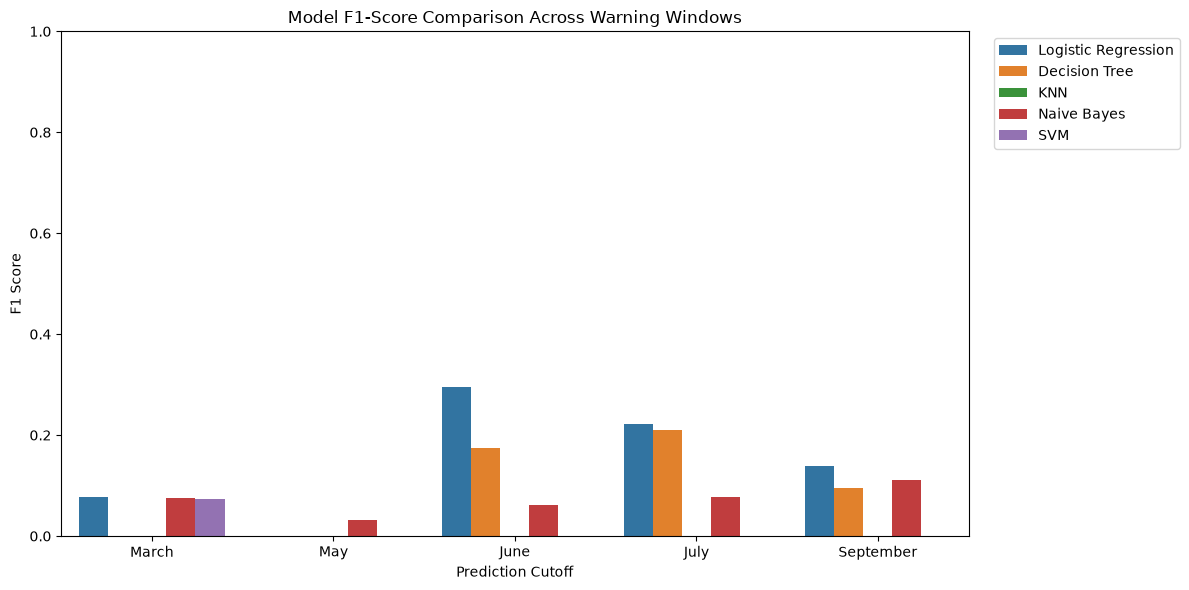

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compare F1 scores across warning windows
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Warning Window",
    y="F1 Score",
    hue="Model"
)

plt.title("Model F1-Score Comparison Across Warning Windows")
plt.xlabel("Prediction Cutoff")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

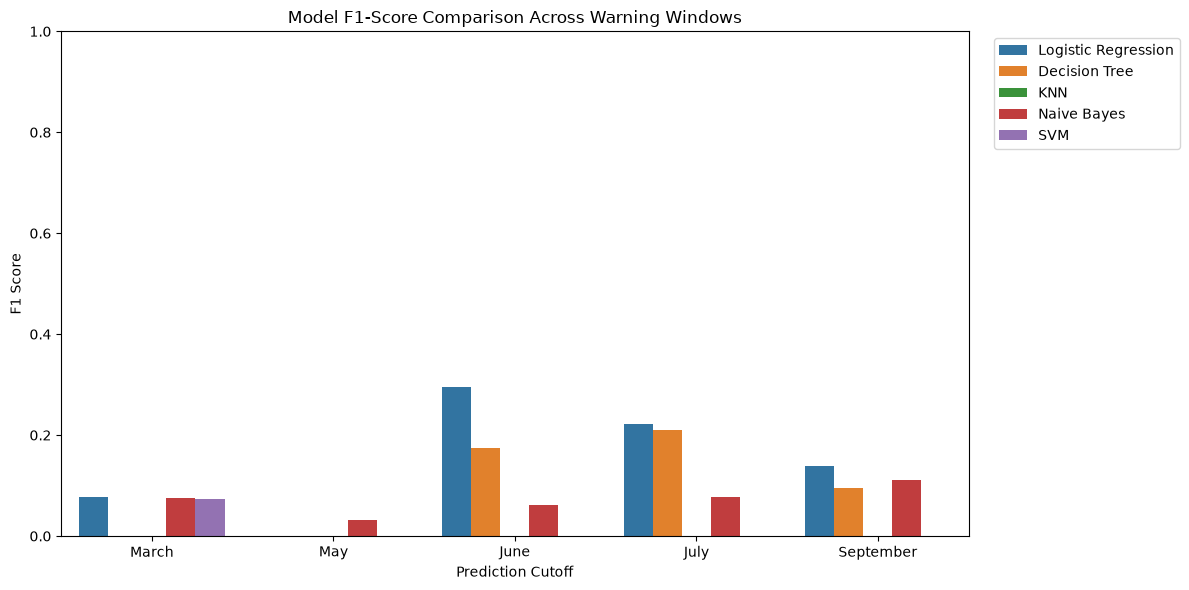

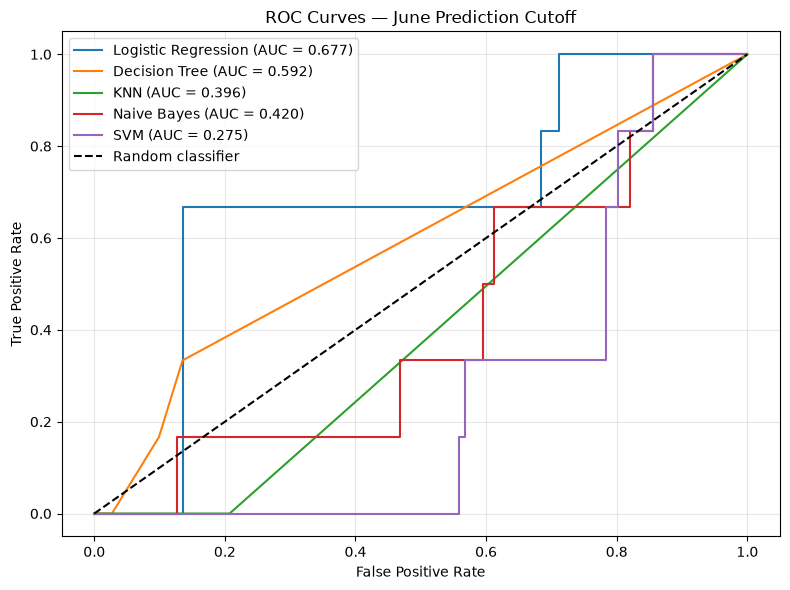

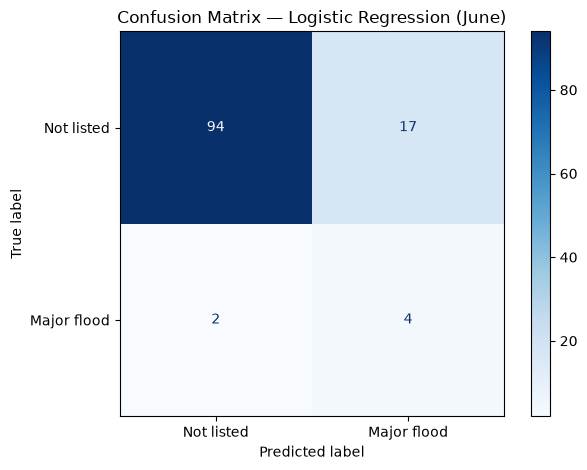

All three figures saved successfully!


In [65]:
from pathlib import Path
from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create figure directory
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

# Save the F1 comparison graph
plt.figure(figsize=(12, 6))
sns.barplot(
    data=results_df,
    x="Warning Window",
    y="F1 Score",
    hue="Model"
)
plt.title("Model F1-Score Comparison Across Warning Windows")
plt.xlabel("Prediction Cutoff")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(figure_dir / "f1_comparison.png", dpi=300)
plt.show()

# ROC curves for all five classifiers using June rainfall
june_data = oof_predictions_df[
    oof_predictions_df["CUTOFF"] == "June"
]

plt.figure(figsize=(8, 6))

for model_name in models.keys():
    subset = june_data[june_data["MODEL"] == model_name]

    fpr, tpr, thresholds = roc_curve(
        subset["ACTUAL"],
        subset["PROBABILITY"]
    )
    model_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{model_name} (AUC = {model_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.title("ROC Curves — June Prediction Cutoff")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figure_dir / "june_roc_curves.png", dpi=300)
plt.show()

# Confusion matrix for Logistic Regression — June
best_data = june_data[
    june_data["MODEL"] == "Logistic Regression"
]

cm = confusion_matrix(
    best_data["ACTUAL"],
    best_data["PREDICTED"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not listed", "Major flood"]
).plot(cmap="Blues")

plt.title("Confusion Matrix — Logistic Regression (June)")
plt.tight_layout()
plt.savefig(figure_dir / "june_confusion_matrix.png", dpi=300)
plt.show()

print("All three figures saved successfully!")

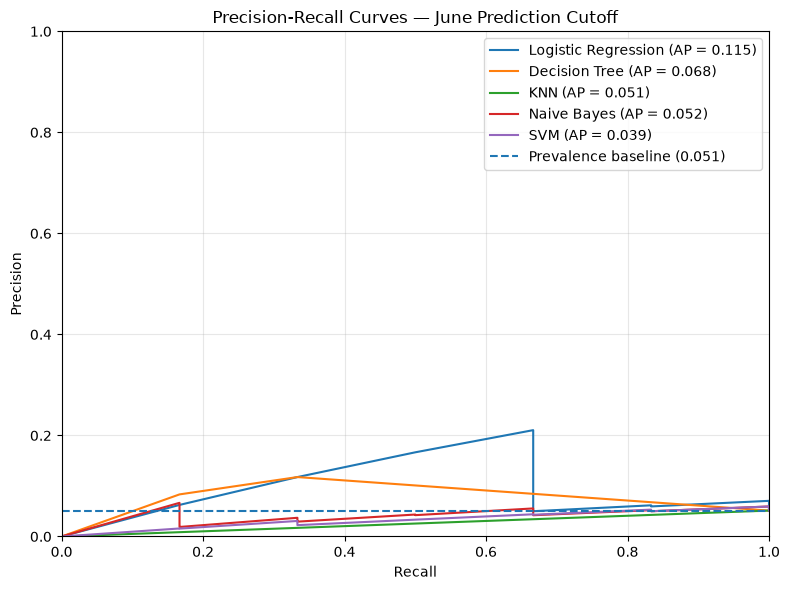

June Precision-Recall figure saved successfully!


In [66]:

# PRECISION-RECALL CURVES: JUNE CUTOFF

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

june_data = oof_predictions_df[
    oof_predictions_df["CUTOFF"] == "June"
]

plt.figure(figsize=(8, 6))

for model_name in models.keys():

    subset = june_data[
        june_data["MODEL"] == model_name
    ]

    precision, recall, thresholds = precision_recall_curve(
        subset["ACTUAL"],
        subset["PROBABILITY"]
    )

    ap = average_precision_score(
        subset["ACTUAL"],
        subset["PROBABILITY"]
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap:.3f})"
    )

# Random-ranking reference: positive-class prevalence
baseline = y.mean()

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Prevalence baseline ({baseline:.3f})"
)

plt.title("Precision-Recall Curves — June Prediction Cutoff")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figure_dir / "june_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("June Precision-Recall figure saved successfully!")


#### Results and Discussion

The five classifiers were evaluated across five rainfall prediction windows using stratified three-fold cross-validation.

Logistic Regression using rainfall from January to June achieved the highest Recall (0.667) and F1-score (0.296) among the tested combinations. Logistic Regression using rainfall through September achieved the highest ROC-AUC (0.737).

For the June Logistic Regression configuration, the pooled out-of-fold confusion matrix contained 94 true negatives, 17 false positives, 2 false negatives and 4 true positives.

The findings suggest that June rainfall features provided the most favourable balance of Recall and F1-score in these experiments. However, the small number of documented flood years limits the reliability and generalisability of the results.

The results should therefore be interpreted as exploratory classification findings rather than evidence of a deployable flood-warning system.


####  Descriptive Baseline: Individual Rainfall Measures

As a supplementary sanity check, individual raw rainfall measures are evaluated against the documented flood-year labels using ROC-AUC.

Unlike the cross-validation experiments, this descriptive comparison uses all 117 observations. It is therefore not an independent predictive performance estimate.


In [67]:
# Descriptive rainfall-only baseline comparison

from pathlib import Path
from sklearn.metrics import roc_auc_score

# Individual rainfall measures
baseline_features = {
    "March": "MAR",
    "May": "MAY",
    "June": "JUN",
    "July": "JUL",
    "JJAS": "JJAS",
    "Annual": "ANNUAL"
}

baseline_results = []

# Calculate ROC-AUC for each individual measure
for rainfall_name, column in baseline_features.items():

    score = roc_auc_score(y, df[column])

    baseline_results.append({
        "Rainfall Measure": rainfall_name,
        "Feature": column,
        "ROC-AUC": score
    })

# Display comparison
baseline_auc_df = pd.DataFrame(baseline_results)

display(baseline_auc_df.round(3))

# Save results for reproducibility
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

baseline_auc_df.to_csv(
    output_dir / "rainfall_only_baseline_auc.csv",
    index=False
)

print("Rainfall-only baseline results saved successfully!")

,Rainfall Measure,Feature,ROC-AUC
0,March,MAR,0.432
1,May,MAY,0.607
2,June,JUN,0.851
3,July,JUL,0.782
4,JJAS,JJAS,0.889
5,Annual,ANNUAL,0.848


Rainfall-only baseline results saved successfully!


#### Logistic Regression Performance Across Prediction Cutoffs

This comparison examines how the recall, F1-score and ROC-AUC of Logistic Regression change as additional monthly rainfall observations become available.

The results are obtained from pooled out-of-fold predictions using stratified three-fold cross-validation.

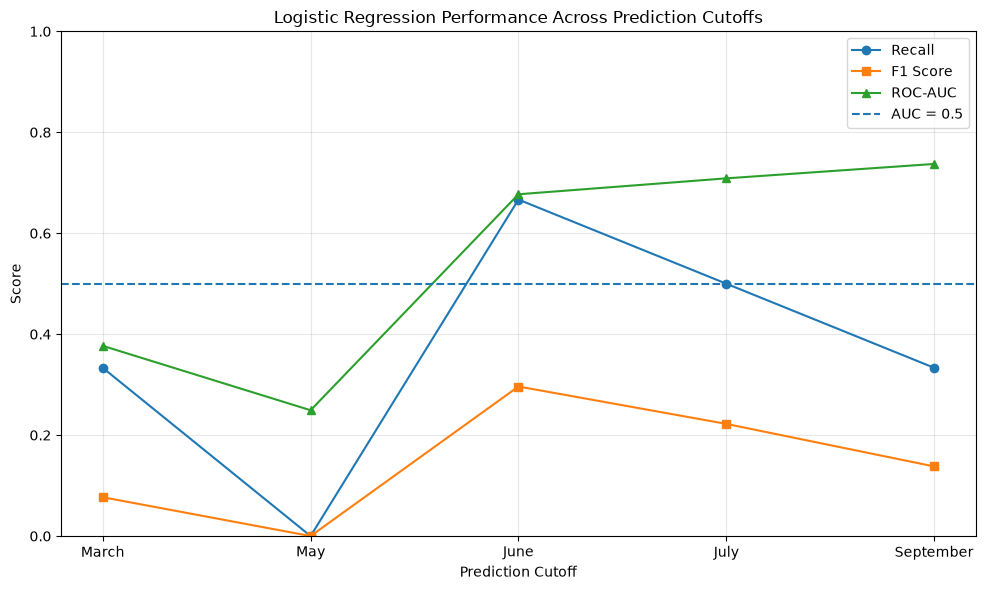

Figure 2 saved successfully!


In [68]:
# Logistic Regression performance across prediction cutoffs

from pathlib import Path
import matplotlib.pyplot as plt

# Define the correct chronological order
cutoff_order = [
    "March", "May", "June", "July", "September"
]

# Filter Logistic Regression results
logistic_results = results_df[
    results_df["Model"] == "Logistic Regression"
].copy()

# Preserve cutoff order
logistic_results["Warning Window"] = pd.Categorical(
    logistic_results["Warning Window"],
    categories=cutoff_order,
    ordered=True
)

logistic_results = logistic_results.sort_values(
    "Warning Window"
)

# Verify that all five cutoffs are present
assert len(logistic_results) == 5, (
    "Expected exactly five Logistic Regression results."
)

# Create the comparison figure
plt.figure(figsize=(10, 6))

cutoffs = logistic_results["Warning Window"].astype(str)

plt.plot(
    cutoffs,
    logistic_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    cutoffs,
    logistic_results["F1 Score"],
    marker="s",
    label="F1 Score"
)

plt.plot(
    cutoffs,
    logistic_results["ROC-AUC"],
    marker="^",
    label="ROC-AUC"
)

# Reference line representing chance-level ROC-AUC
plt.axhline(
    y=0.5,
    linestyle="--",
    label="AUC = 0.5"
)

plt.title(
    "Logistic Regression Performance Across Prediction Cutoffs"
)
plt.xlabel("Prediction Cutoff")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

# Save figure
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "logistic_cutoff_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 saved successfully!")

In [69]:
import math

# June Logistic Regression predictions
best_data = oof_predictions_df[
    (oof_predictions_df["CUTOFF"] == "June") &
    (oof_predictions_df["MODEL"] == "Logistic Regression")
]

# Calculate true positives and false negatives
tp = (
    (best_data["ACTUAL"] == 1) &
    (best_data["PREDICTED"] == 1)
).sum()

fn = (
    (best_data["ACTUAL"] == 1) &
    (best_data["PREDICTED"] == 0)
).sum()

n = tp + fn
p = tp / n

# 95% Wilson confidence interval
z = 1.959963984540054

denominator = 1 + (z ** 2 / n)

centre = (p + z ** 2 / (2 * n)) / denominator

margin = (
    z * math.sqrt(
        p * (1 - p) / n +
        z ** 2 / (4 * n ** 2)
    ) / denominator
)

lower = centre - margin
upper = centre + margin

print("Recall:", round(p, 3))
print("95% Wilson confidence interval:")
print(f"({lower:.2f}, {upper:.2f})")

Recall: 0.667
95% Wilson confidence interval:
(0.30, 0.90)


In [71]:
# Summarise variation in metrics across validation folds

fold_summary = (
    fold_metrics_df
    .groupby(["Warning Window", "Model"])
    .agg(
        Recall_Mean=("Recall", "mean"),
        Recall_Std=("Recall", "std"),
        F1_Mean=("F1 Score", "mean"),
        F1_Std=("F1 Score", "std"),
        AUC_Mean=("ROC-AUC", "mean"),
        AUC_Std=("ROC-AUC", "std"),
        PR_AUC_Mean=("PR-AUC (Average Precision)", "mean"),
        PR_AUC_Std=("PR-AUC (Average Precision)", "std")
    )
    .reset_index()
    .round(3)
)

display(fold_summary)

# Save fold variability summary
fold_summary.to_csv(
    output_dir / "fold_variability_summary.csv",
    index=False
)

print("Fold variability summary:", fold_summary.shape)
print("Saved successfully!")

,Warning Window,Model,Recall_Mean,Recall_Std,F1_Mean,F1_Std,AUC_Mean,AUC_Std,PR_AUC_Mean,PR_AUC_Std
0,July,Decision Tree,0.333,0.289,0.178,0.168,0.617,0.116,0.097,0.050
1,July,KNN,0.000,0.000,0.000,0.000,0.419,0.014,0.051,0.000
2,July,Logistic Regression,0.500,0.500,0.172,0.183,0.766,0.199,0.272,0.155
3,July,Naive Bayes,0.167,0.289,0.056,0.096,0.514,0.304,0.102,0.052
4,July,SVM,0.000,0.000,0.000,0.000,0.437,0.250,0.081,0.033
5,June,Decision Tree,0.333,0.289,0.156,0.145,0.599,0.124,0.086,0.037
6,June,KNN,0.000,0.000,0.000,0.000,0.396,0.016,0.051,0.000
7,June,Logistic Regression,0.667,0.577,0.274,0.286,0.707,0.237,0.202,0.188
8,June,Naive Bayes,0.167,0.289,0.042,0.072,0.459,0.286,0.082,0.033
9,June,SVM,0.000,0.000,0.000,0.000,0.266,0.113,0.053,0.007


Fold variability summary: (25, 10)
Saved successfully!
